In [10]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import PIL
import PIL.ImageFilter
import PIL.ImageEnhance
import random

# Part 1 - Exploratory Data Analysis ("EDA")

In [11]:
DATA_FOLDER = './images'

In [13]:


def get_classes(folder: str, f = lambda x, y, z: len(z)) -> dict[dict[str, any]]:
    d_ = {}
    #dd_ = {}
    len_data_folder = len(folder)
    for root, dirnames, filenames in os.walk(folder):
        print(root)
        if not dirnames:
            pic_class_ = root[(len_data_folder + 1):]
            y_ = f(root, dirnames, filenames)
            #dd_[pic_class_] = n_
            sep_ = pic_class_.find('_')
            if -1 == sep_:
                return None
            leaf_ = pic_class_[:sep_]
            affliction_ = pic_class_[(sep_ + 1):]
            if leaf_ not in d_:
                d_[leaf_] = {affliction_: y_}
            else:
                d_[leaf_][affliction_] = y_
    return d_#, dd_


def put_distribution(data: dict[dict[str, int]]) -> None:
    df = pd.DataFrame.from_dict(data)
    print(df)
    pd.DataFrame(df.sum()).plot.bar()
    df.plot.bar()
    df.plot.pie(subplots=True)

def put_pictures(folder: str) -> None:
    files = get_classes(folder, lambda x, y, z : [f"{x}/{s}" for s in z[:4]])
    for f_leaf in files:
        f_ = files[f_leaf]
        pics = list(f_.values())
        n = len(pics)
        m = len(pics[0])
        f, axarr = plt.subplots(n,m)
        f.tight_layout()
        plt.suptitle(f"{f_leaf}")
        for i, f_affliction in enumerate(f_):
            for j, path in enumerate(pics[i]):
                img = mpimg.imread(path)
                ax = axarr[i,j]
                ax.imshow(img)
                ax.set_xticks([])
                ax.set_yticks([])
                ax.title.set_text(f"{f_affliction}_{j}")
        plt.show()


./images
./images/Grape_Esca
./images/Apple_rust
./images/Apple_healthy
./images/Apple_Black_rot
./images/Grape_spot
./images/Grape_Black_rot
./images/Grape_healthy
./images/Apple_scab
            Grape   Apple
Esca       1382.0     NaN
spot       1075.0     NaN
Black_rot  1178.0   620.0
healthy     422.0  1640.0
rust          NaN   275.0
scab          NaN   629.0


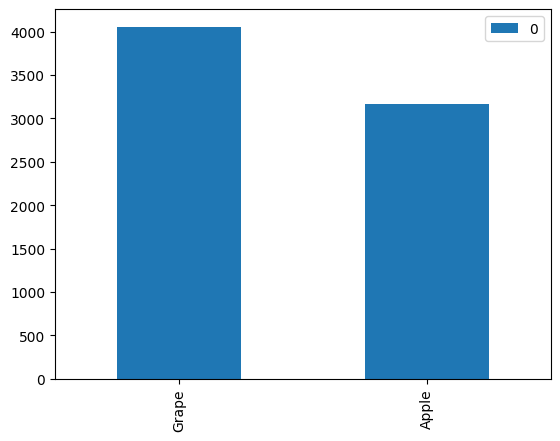

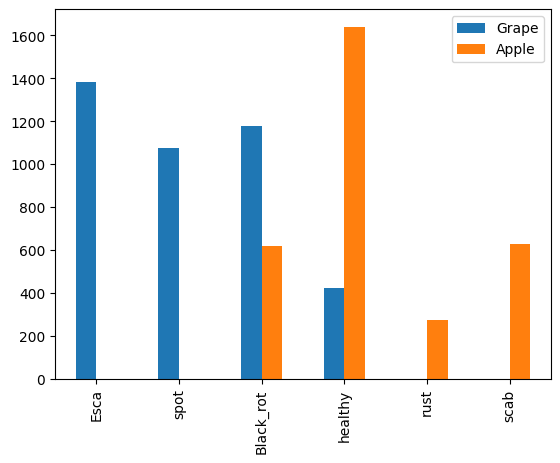

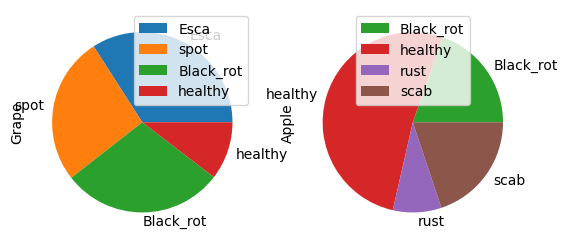

In [14]:
data = get_classes(DATA_FOLDER)
put_distribution(data)

./images
./images/Grape_Esca
./images/Apple_rust
./images/Apple_healthy
./images/Apple_Black_rot
./images/Grape_spot
./images/Grape_Black_rot
./images/Grape_healthy
./images/Apple_scab


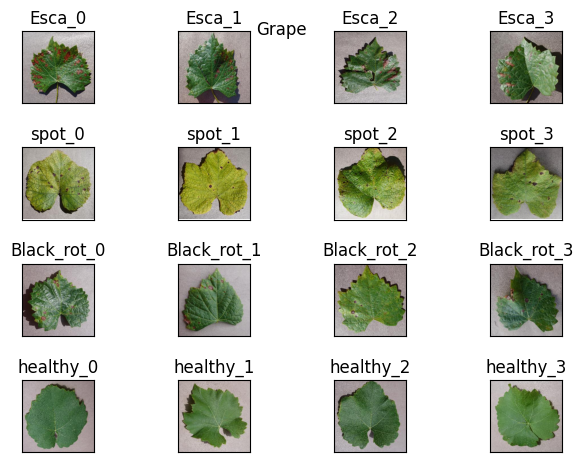

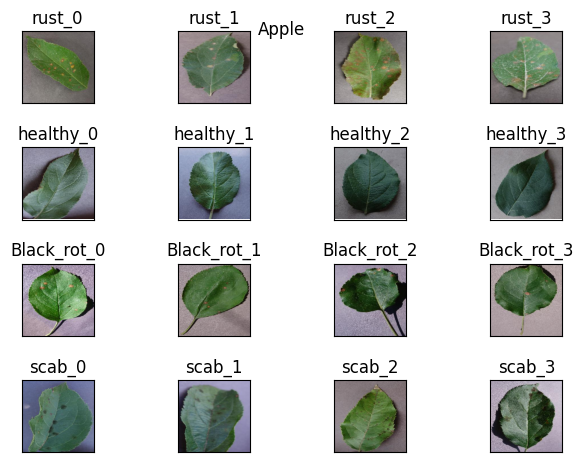

In [15]:
put_pictures(DATA_FOLDER)

# Part 2 - Augmentation

In [27]:
x = random.gauss(mu=0.0, sigma=1.0) #normal
#[0 1[
x = random.randint(0, 360) #[a b]
#[0 1[
x = random.random() #[0 1[
print(x)

0.2949924830812374


In [12]:
def rot_im(im: any, r = None) -> any:
    if r is None:
        r = random.randint(-45, 45)
    return im.rotate(r)

def blur_im(im: any, r = None) -> any:
    max_blur = 3
    if r is None:
        r = random.randint(0, 2 * max_blur)
    if r < max_blur:
        return im.filter(PIL.ImageFilter.BoxBlur(1 + r % max_blur))
    return im.filter(PIL.ImageFilter.GaussianBlur(1 + r % max_blur))

def contrast_im(img, r = None):
    if r is None:
        r = random.randint(-128 // 2, 128 // 2)
    factor = (259 * (r + 255)) / (255 * (259 - r))
    def contrast(c):
        value = 128 + factor * (c - 128)
        return value
    return img.point(contrast)

def zoom_im(img):
    w, h = img.size
    x = random.randint(3 * w // 8, 5 * w // 8)
    y = random.randint(3 * h // 8, 4 * h // 8)
    zoom = random.gauss(mu=1.0, sigma=0.2) * 2
    mod = img.crop((x - w / zoom, y - h / zoom, 
                    x + w / zoom, y + h / zoom))
    return mod.resize((w, h), PIL.Image.LANCZOS)

def brighten_im(img, r = None):
    if r is None:
        r = random.gauss(mu=1.0, sigma=0.3)
    mod = PIL.ImageEnhance.Brightness(img)
    return mod.enhance(r)

def perspective_im(img):
    def find_coeffs(pa, pb):
        matrix = []
        for p1, p2 in zip(pa, pb):
            matrix.append([p1[0], p1[1], 1, 0, 0, 0, -p2[0]*p1[0], -p2[0]*p1[1]])
            matrix.append([0, 0, 0, p1[0], p1[1], 1, -p2[1]*p1[0], -p2[1]*p1[1]])
    
        A = np.matrix(matrix, dtype=float)
        B = np.array(pb).reshape(8)
    
        res = np.dot(np.linalg.inv(A.T * A) * A.T, B)
        return np.array(res).reshape(8)
    width, height = img.size
    r_max = min(width, height) // 10
    def rand_coef(l: list[int]) -> list[int]:
        pb = []
        for pt in l:
            pb.append(tuple([e + random.randint(-r_max, r_max) for e in list(pt)]))
        return pb
    pa = [(0, 0), (width, 0), (width, height), (0, height)]
    pb = rand_coef(pa)
    coeffs = find_coeffs(pa, pb)
    return img.transform((width, height), 
                        PIL.Image.PERSPECTIVE, 
                        coeffs,
                        PIL.Image.BICUBIC)

def transform_file(path: str) -> None:
    img = PIL.Image.open(path)
    tf = {'default': lambda x: x,
          'rot': rot_im,
          'blur': blur_im,
          'contrast': contrast_im,
          'zoom': zoom_im,
          'brighten': brighten_im,
          'perspective': perspective_im}
    n = 5
    f, axarr = plt.subplots(n, len(tf))
    f.set_figheight(15)
    f.set_figwidth(15)
    f.tight_layout()
    plt.suptitle(f"Transforms")
    for j in range(5):
        for i, name in enumerate(tf):
            ax = axarr[j, i]
            mod = tf[name](img)
            ax.imshow(mod)
            ax.set_xticks([])
            ax.set_yticks([])
            ax.title.set_text(f"{name}_{j}")
    plt.show()

In [ ]:
# files = get_classes(DATA_FOLDER, lambda x, y, z : f"{x}/{z[0]}")
# file = next(iter(next(iter(files.values())).values()))

# transform_file(file)

# Part 3 - Image Transformations

In [ ]:
!pip install rembg onnxruntime albumentations markupsafe tqdm --quiet 

In [13]:
import albumentations as A
import cv2
from rembg import remove as remove_bg
from pathlib import Path
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from pprint import pprint
from tqdm import tqdm

In [14]:
def remove_background(file_path: str):
    img = cv2.imread(file_path)
    output = remove_bg(img)
    return output[:,:,:3]

def desaturate_green(img: np.ndarray):
    b,g,r = cv2.split(img)
    green_desaturated = np.clip(g*.75,0,255).astype(np.uint8)
    return cv2.merge((b,green_desaturated,r))

def increase_contrast(img, factor: float = 1.25):
    img = img.astype(np.float32)
    mean = img.mean()
    contrasted = mean + factor * (img - mean)
    return np.clip(contrasted, 0, 255).astype(np.uint8)

def saturate_green(img: np.ndarray, factor: int = 2):
    b,g,r = cv2.split(img)
    green_saturated = np.clip(g*factor,0,255).astype(np.uint8)
    return cv2.merge((b,green_saturated,r))

def center_crop(img: np.ndarray, target_size: int = 64, p: float | int = 1.):
    transform = A.Compose([
        A.CenterCrop(height=target_size, width=target_size)])
    transformed = transform(image=img)
    return transformed['image']

def random_crop(img: np.ndarray, target_size: int = 64, p: float | int = 1.):
    transform = A.Compose([A.RandomSizedCrop(
        min_max_height=(64, 64),
        size=(64, 64),
        w2h_ratio=1.0,
        interpolation=cv2.INTER_LINEAR,
        mask_interpolation=cv2.INTER_NEAREST,
        area_for_downscale="image.",  # Use INTER_AREA for image downscaling
        p=p
    )])
    return transform(image=img)['image']

def invert_img(img:np.ndarray):
    return np.invert(img)

def downscale_img(img: np.ndarray, scale_range: tuple=(.25,.25)):
    downscale = A.Downscale(
        scale_range=scale_range,
        p=1)
    return downscale(image=img)['image']

def random_crop_img(file_path: str, crop_size: tuple = (64,64)):
    """
    def random_crop_img(file_path: str, crop_size: tuple = (64,64)):
        Performs min_max normalization on image matrix. 
    """
    image = cv2.imread(file_path)  # 256x256 expected
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    transform = A.Compose([
        A.RandomCrop(width=crop_size[0], height=crop_size[1]),
        A.PadIfNeeded(min_height=256, min_width=256,
                      border_mode=cv2.BORDER_CONSTANT, 
                      value=0)])
    
    augmented = transform(image=image)
    augmented_image = augmented["image"]
    return augmented_image

def flip_img(img: np.ndarray, horizontal: bool = True) -> np.ndarray:
    return cv2.flip(img, horizontal)

def normalize_img(img: np.ndarray) -> np.ndarray:
    """
    def normalize_img(img: np.ndarray)
        -> np.ndarray:
    Performs min_max normalization on image matrix. 
    """
    return cv2.normalize(img, None, alpha=5, beta=255, norm_type=cv2.NORM_MINMAX)

# def green_mask(img:np.ndarray) -> np.ndarray:
#     hsv_img = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
#     # lower_green = np.array([35, 0, 50])
#     # upper_green = np.array([85, 255, 255])
#     lower_green = np.array([25, 30, 30])    # Hue ↓, include olive/lime greens
#     upper_green = np.array([95, 255, 255])  # Hue ↑, include teal/turquoise greens
#     kernel = np.ones((5,5), np.uint8)

#     green_mask = cv2.inRange(hsv_img, lower_green, upper_green)
#     green_mask = cv2.morphologyEx(green_mask, cv2.MORPH_OPEN, kernel)
#     green_mask = cv2.morphologyEx(green_mask, cv2.MORPH_CLOSE, kernel)
#     green_saturated_img = saturate_green(hsv_img, factor=.5)

#     green_img = cv2.bitwise_and(img, img, mask=green_mask)
#     green_img = remove_bg(green_img)
#     return green_img

def add_noise_to_img(img: np.ndarray) -> np.ndarray:
    """
    def add_noise_to_img(img: np.ndarray) 
        -> np.ndarray:
    Adds random gaussian noise to the image. 
    """
    mean = 0.
    std = 10.
    noise = np.random.normal(mean, std, img.shape).astype('uint8')
    noisy_image = cv2.add(img, noise)
    return noisy_image

def composite_00(img:np.ndarray):
    """
    def composite_00(img:np.ndarray) 
        -> np.ndarray:
    Saturate green, increase contrast, blur. 
    Weighted merge with initial image.
    Applying grayscale. Removing background.
    ==> Allows to identify leave shapes and inner
    structures. 
    """
    copy_img = img.copy()
    img = saturate_green(img, factor=1.5)
    img = increase_contrast(img, factor=1.5)
    img = cv2.medianBlur(img,5)
    superpose = cv2.addWeighted(img, .9, copy_img, .1, 10)
    superpose = cv2.cvtColor(superpose, cv2.COLOR_RGB2GRAY)
    superpose = remove_bg(superpose)
    return superpose

def composite_01(img: np.ndarray):
    """
    def composite_01(img: np.ndarray)
        -> np.ndarray:
    Convert to HLS. Increase contrasts and luminosity.
    Applies successive color and contrast transformations.
    Removes background. Desaturate green. 
    ==> Useful to identify black spots and leaves
    structure integrity.
    """
    img = cv2.cvtColor(img, cv2.COLOR_RGB2HLS)
    img = cv2.convertScaleAbs(img, alpha=.5, beta=15)
    img = increase_contrast(img, factor=1.3)
    img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    img = cv2.convertScaleAbs(img, alpha=1.55, beta=15)
    img = increase_contrast(img, factor=1.5)
    img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    img = increase_contrast(img, factor=1.5)
    img = remove_bg(img)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2HLS)
    img = increase_contrast(img, factor=1.3)
    img = desaturate_green(img)
    img = normalize_img(img)
    return img
    
def composite_02(img: np.ndarray) -> np.ndarray:
    """
    def composite_02(img: np.ndarray) 
        -> np.ndarray:
    Applies HSV filter, identifies blueish areas and create a specific 
    mask. Turns all values from mask to 255, 128, 128 which makes
    them look yellow/redish. Superpose mask at par with initial \
    image and remove background. 
    ==> Allows to identify colored spots in the image. 
    """
    hsv_img = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    kernel = np.ones((3,3), np.uint8)
    lower_blue = np.array([90, 50, 40])
    upper_blue = np.array([140, 255, 255])
    blue_mask = cv2.inRange(hsv_img, lower_blue, upper_blue)
    blue_mask = cv2.morphologyEx(blue_mask, cv2.MORPH_OPEN, kernel)
    blue_mask = cv2.morphologyEx(blue_mask, cv2.MORPH_CLOSE, kernel)
    empty_mask = np.zeros((*blue_mask.shape, 3), dtype=np.uint8)
    blue_img = cv2.bitwise_and(img, hsv_img, mask=blue_mask)
    mask_color = np.array([255, 128, 128], dtype=np.uint8) 
    mask = np.any(blue_img > 0, axis=-1)
    blue_img[mask] = mask_color
    superpose = cv2.addWeighted(img, .5, blue_img, .5, 0)
    superpose = remove_bg(superpose)
    return superpose

In [15]:
class LeafflictionAugmentation: 

    augmented_images: list[str] = []
    
    def __init__(self, img_folder: str, export_augmented: bool=True, shuffle: bool=True):
        self.img_folder = img_folder
        self.classes, self.image_paths = self.get_classes_and_paths(img_folder)
        if shuffle is True: 
            np.random.shuffle(self.image_paths)

        # i = break juste pour te montrer les augmentations
        i = 0
        for sample in tqdm(self.image_paths):
            if i == 10:
                break
            
            augmentations = self.augment_file(sample)
            if export_augmented is True:
                new_files_list = self.export_file_augmentations(augmentations, sample)
            
            i += 1
            
            
    def export_file_augmentations(self, augmented_img: object, file_path: str) -> None:
        p = Path(file_path).resolve()  # Ensures absolute path
        export_folder = str(p.parent)
        img_name = file_path.split('/')[-1].split('.')[0]
        for label in augmented_img.keys():
            img = augmented_img[label]
            export_path = f"{export_folder}/{img_name}-{label}.png"
            img.save(export_path)
            self.augmented_images.append(export_path)

    def display_augmentations(self, tf: object, file_path: str) -> None:
        n_rows, n_cols = 4, 4
        f, axarr = plt.subplots(n_rows, n_cols, figsize=(15, 9))
        f.tight_layout(pad=3.0)
        plt.suptitle(file_path, fontsize=16, y=1.02)
        
        for idx, (name, mod) in enumerate(tf.items()):
            row, col = divmod(idx, n_cols)
            ax = axarr[row][col]
            ax.imshow(mod)
            ax.axis('off')
            ax.set_title(name)
        
        # If tf has fewer than 15 items, hide extra axes
        for idx in range(len(tf), n_rows * n_cols):
            row, col = divmod(idx, n_cols)
            axarr[row][col].axis('off')
        plt.show()
    
    def augment_file(self, file_path: str) -> object:
        img = PIL.Image.open(file_path)
        np_array_img = np.array(img)
        no_bg_img = remove_background(file_path)
        tf = {
            # J
              'rot': rot_im(img),
              'blur': blur_im(img),
              'contrast': contrast_im(img),
              'zoom': zoom_im(img),
              'brighten': brighten_im(img),
              'perspective': perspective_im(img),
            # M
              'downscaled': Image.fromarray(downscale_img(np_array_img, scale_range=(.25,.25))),
              'downscaled_10': Image.fromarray(downscale_img(np_array_img, scale_range=(.1,.1))),
              'horizontal_mirror': Image.fromarray(flip_img(np_array_img, horizontal=1)),
              'vertical_mirror': Image.fromarray(flip_img(np_array_img, horizontal=0)),
              'noisy': Image.fromarray(add_noise_to_img(np_array_img)),
              'normalized': Image.fromarray(normalize_img(np_array_img)),
              'random_crop': Image.fromarray(random_crop_img(file_path, crop_size=(128,128))),
              'composite00': Image.fromarray(composite_00(np_array_img)),
              'composite01': Image.fromarray(composite_01(no_bg_img)),
              'composite02': Image.fromarray(composite_02(np_array_img)),
            }
        self.display_augmentations(tf, file_path)
        return tf
        
    def get_classes_and_paths(self, root_folder: str) -> list[str]:
        image_extensions = ('.jpg', '.jpeg', '.png')
        image_paths = []
        classes = []

        for dirpath, _, filenames in os.walk(root_folder):
            if _ not in classes and _ != []:
                classes = _ 
            for file in filenames:
                if file.lower().endswith(image_extensions):
                    full_path = os.path.join(dirpath, file)
                    image_paths.append(full_path)
        return classes, image_paths

/tmp/ipykernel_72806/1980996580.py:58: UserWarning: Argument(s) 'value' are not valid for transform PadIfNeeded
  A.PadIfNeeded(min_height=256, min_width=256,


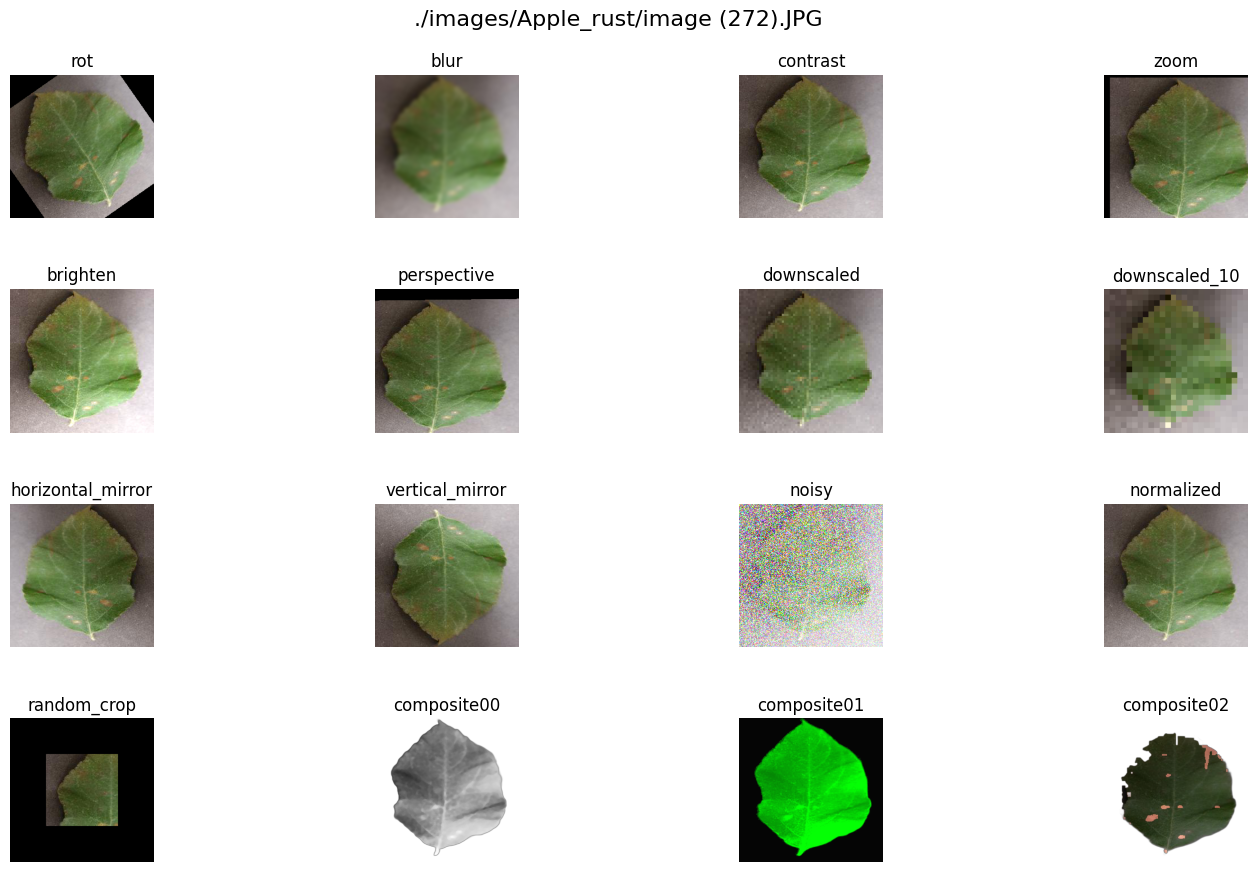

  0%|                                       | 1/7221 [00:08<16:37:49,  8.29s/it]

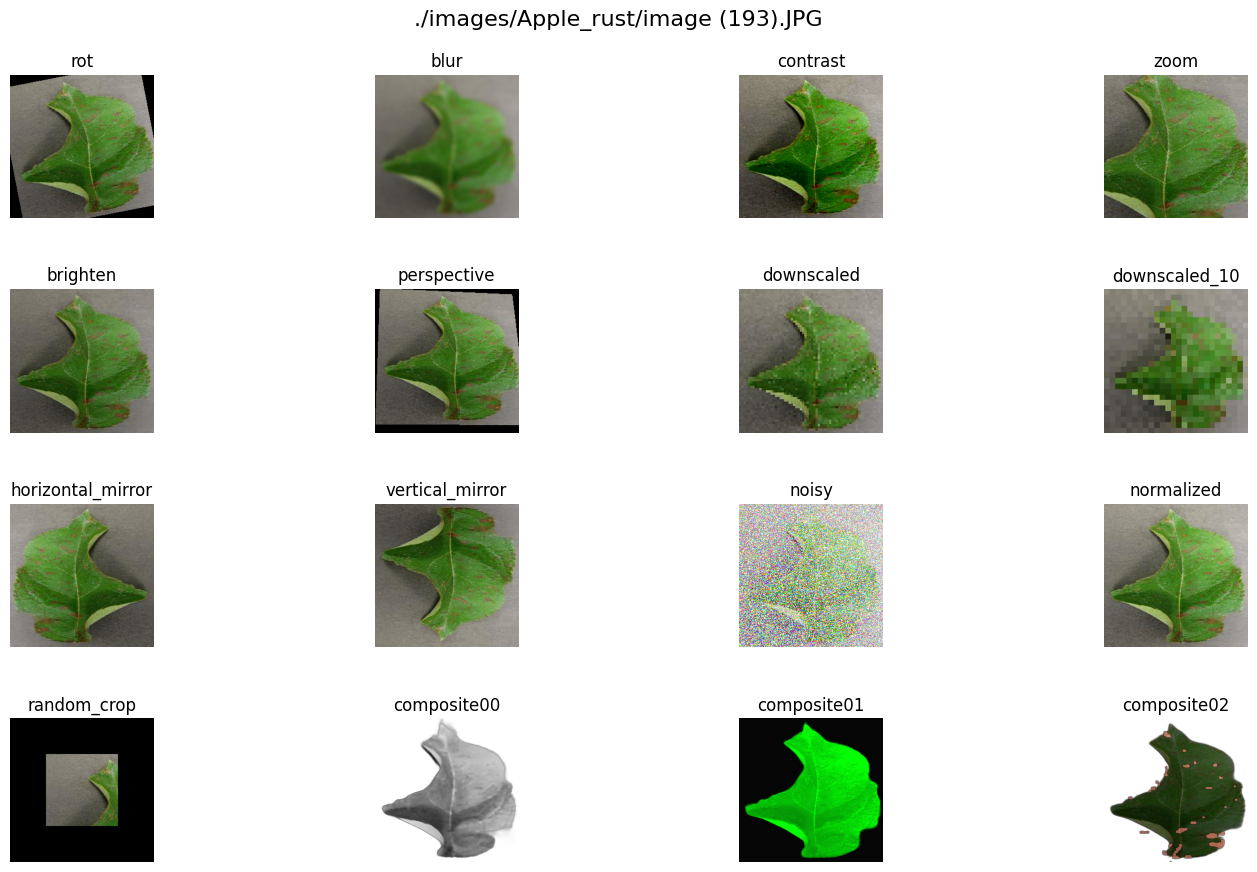

  0%|                                       | 2/7221 [00:14<13:41:35,  6.83s/it]

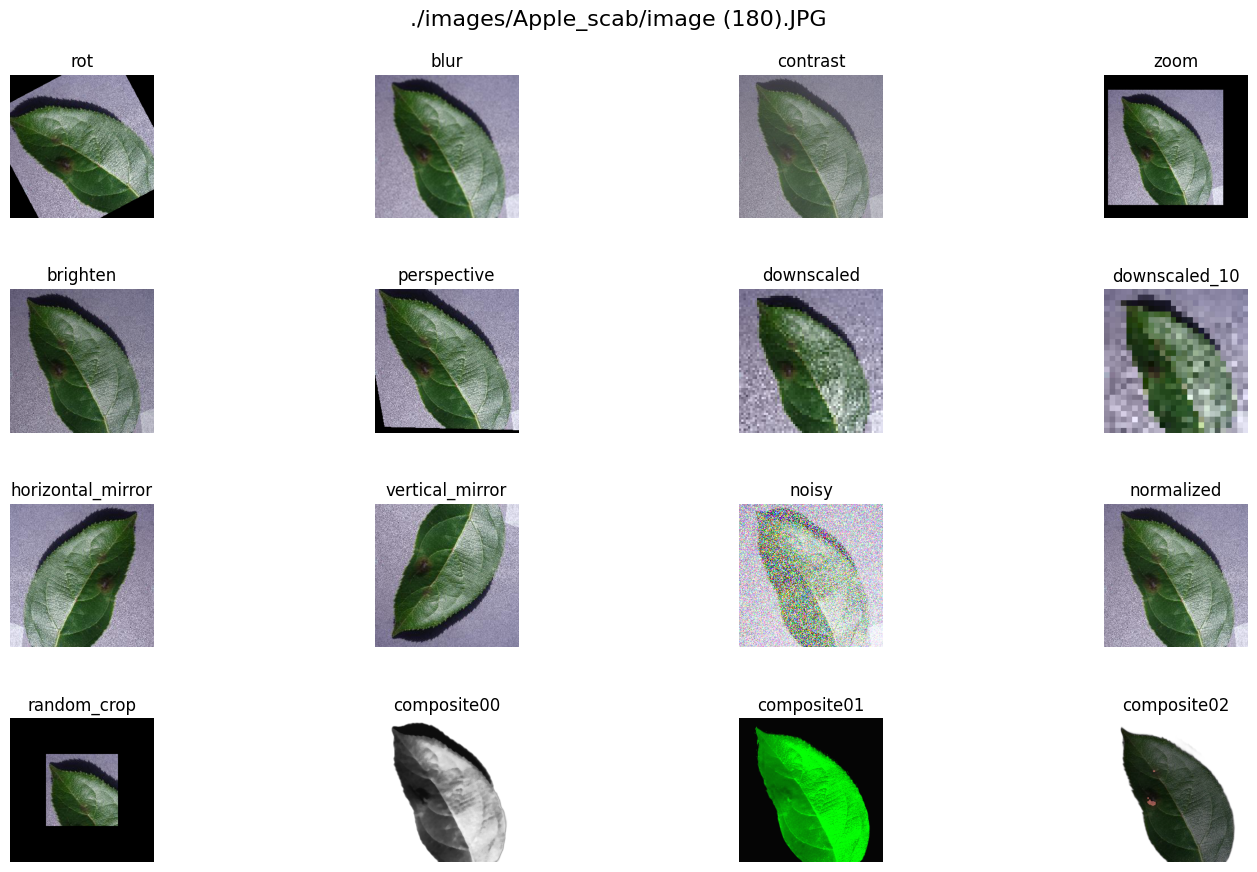

  0%|                                       | 3/7221 [00:19<12:20:10,  6.15s/it]

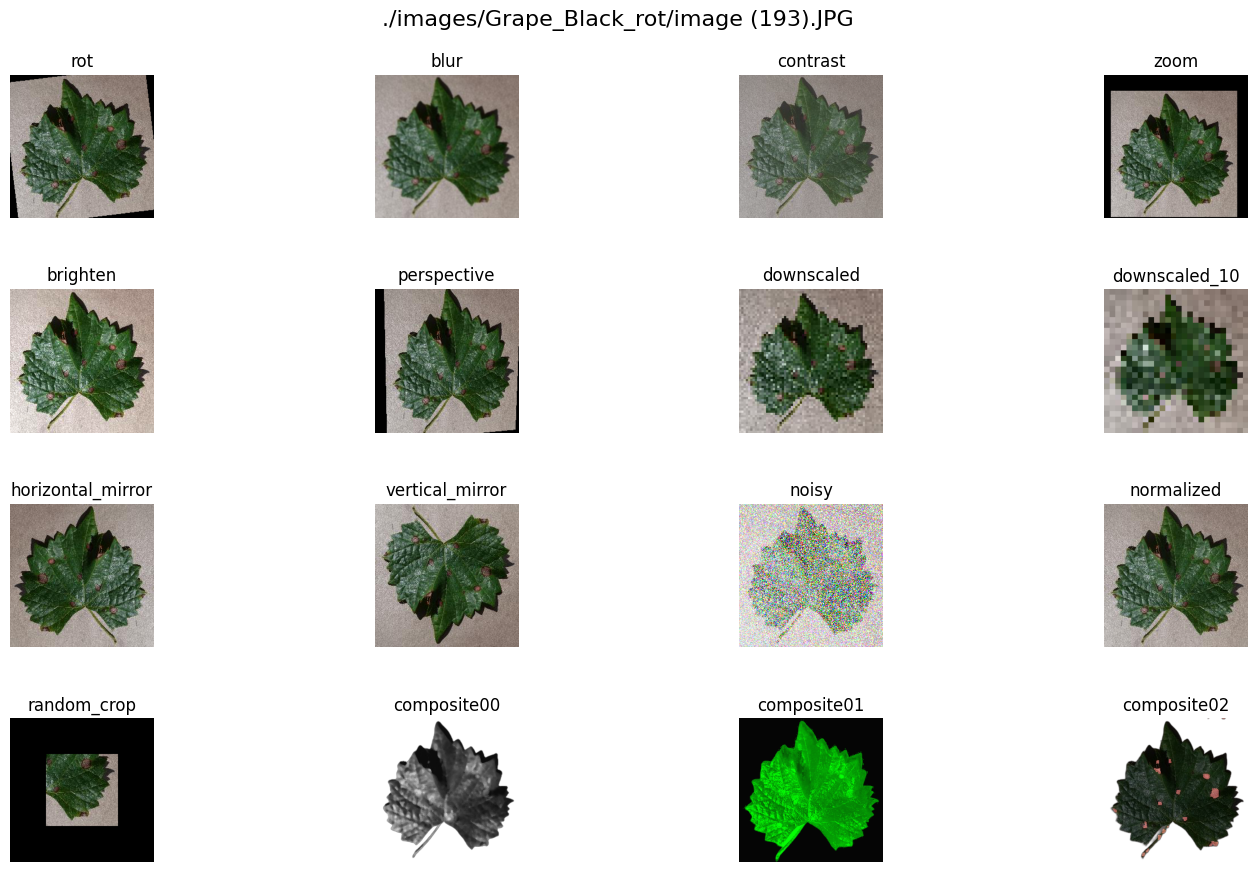

  0%|                                       | 4/7221 [00:24<11:49:23,  5.90s/it]

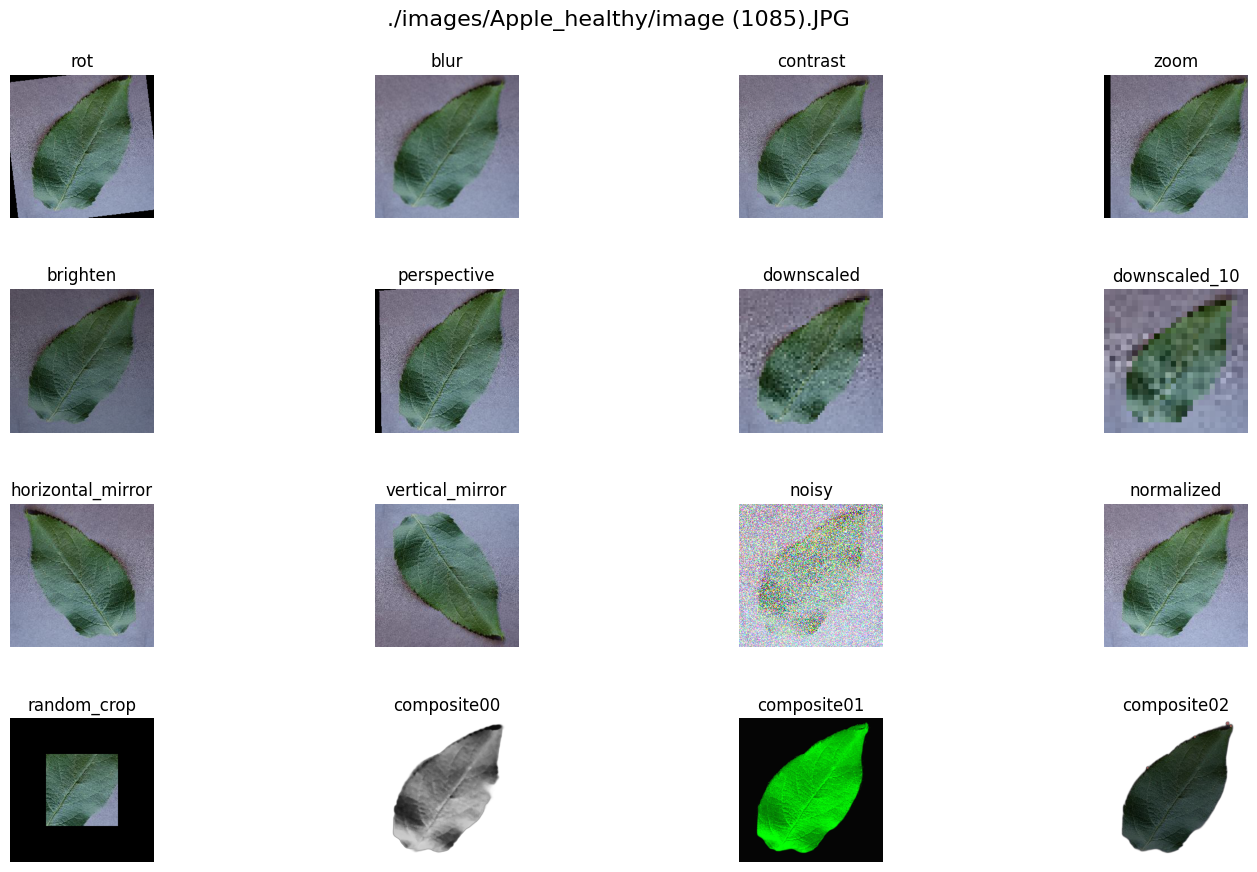

  0%|                                       | 5/7221 [00:30<11:42:26,  5.84s/it]

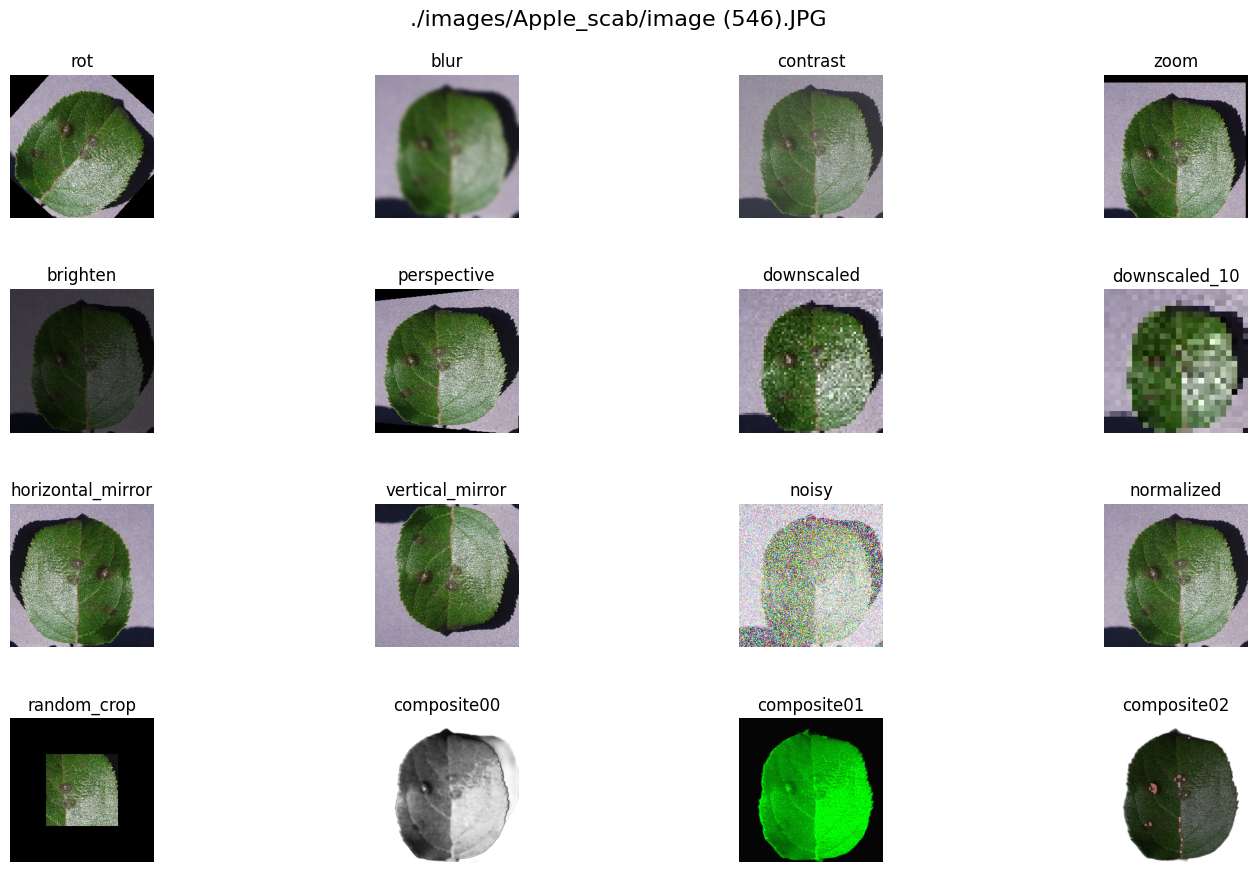

  0%|                                       | 6/7221 [00:36<11:24:28,  5.69s/it]

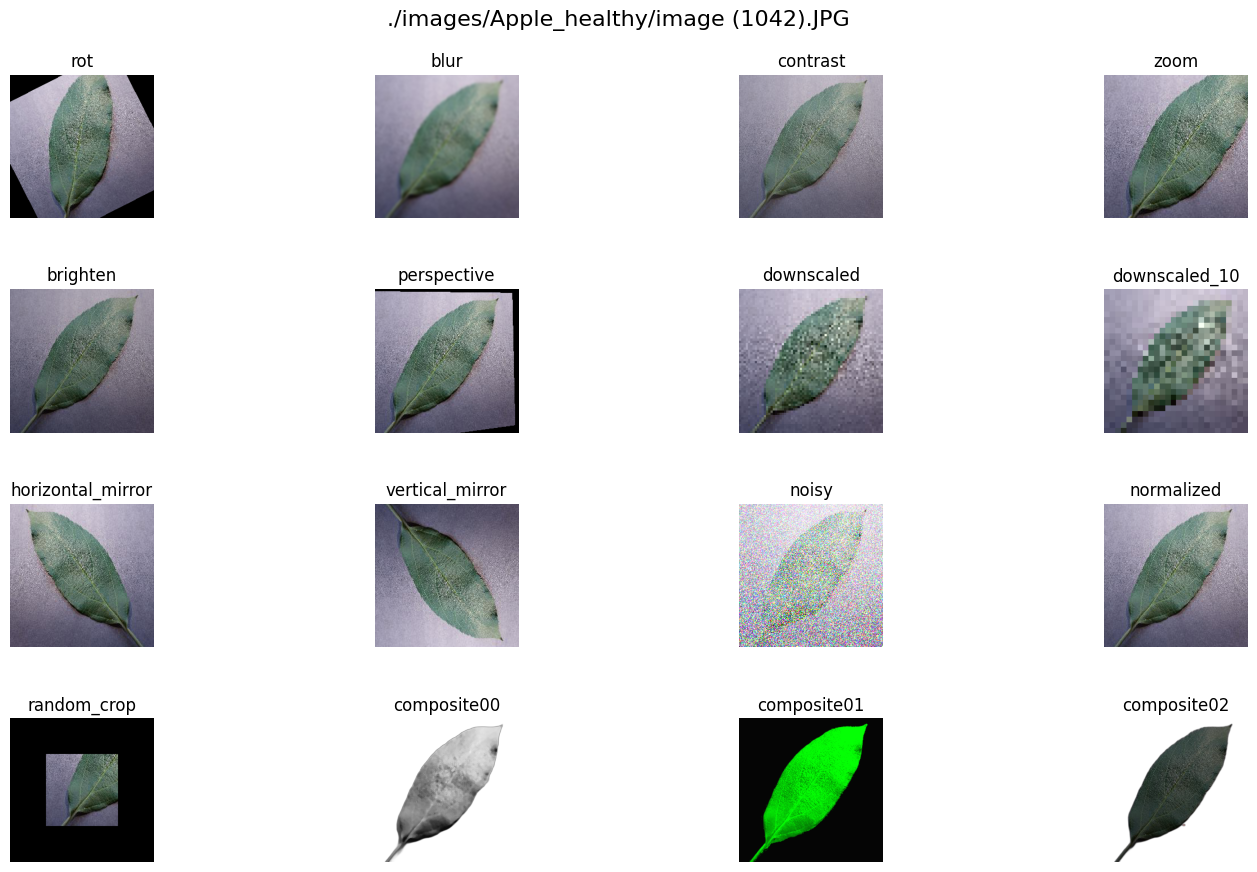

  0%|                                       | 7/7221 [00:41<11:17:40,  5.64s/it]

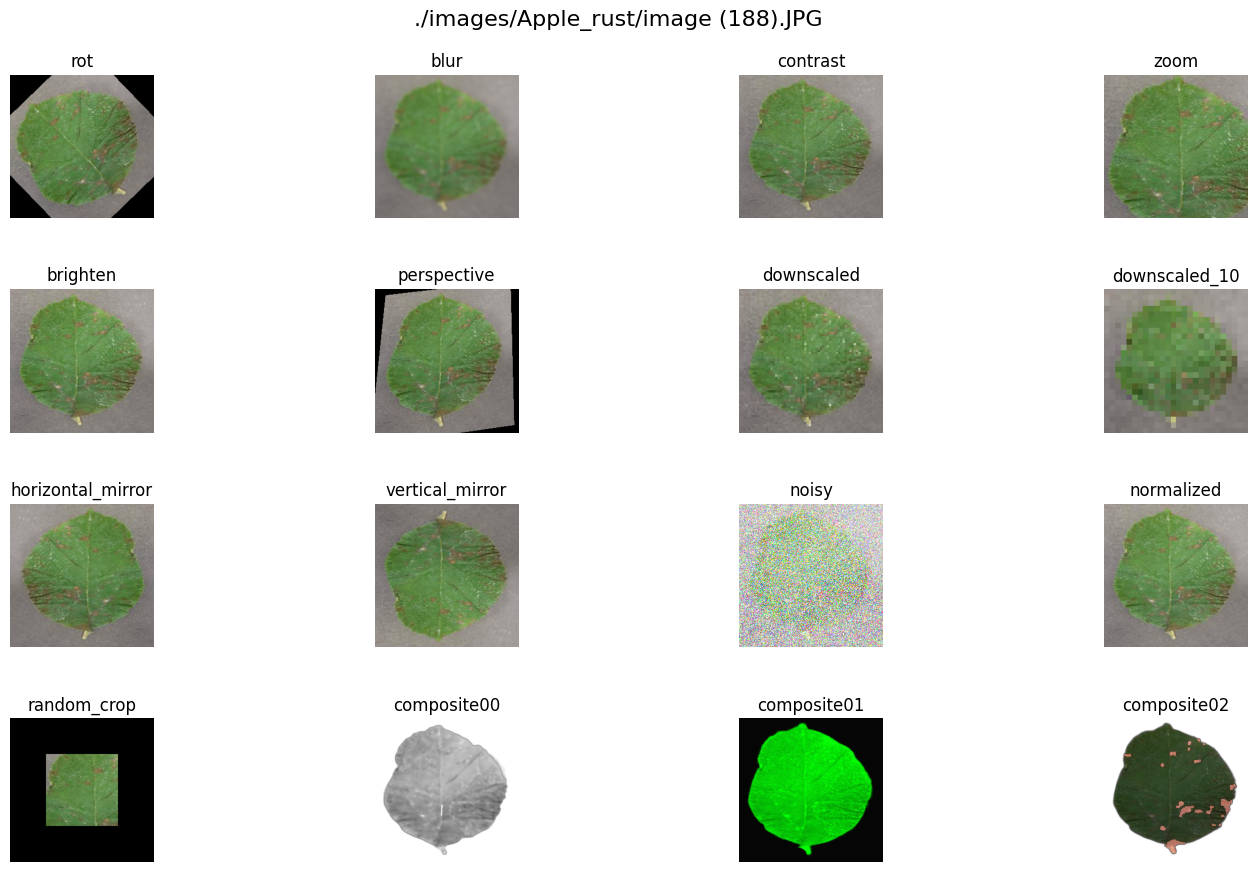

  0%|                                       | 8/7221 [00:47<11:17:16,  5.63s/it]

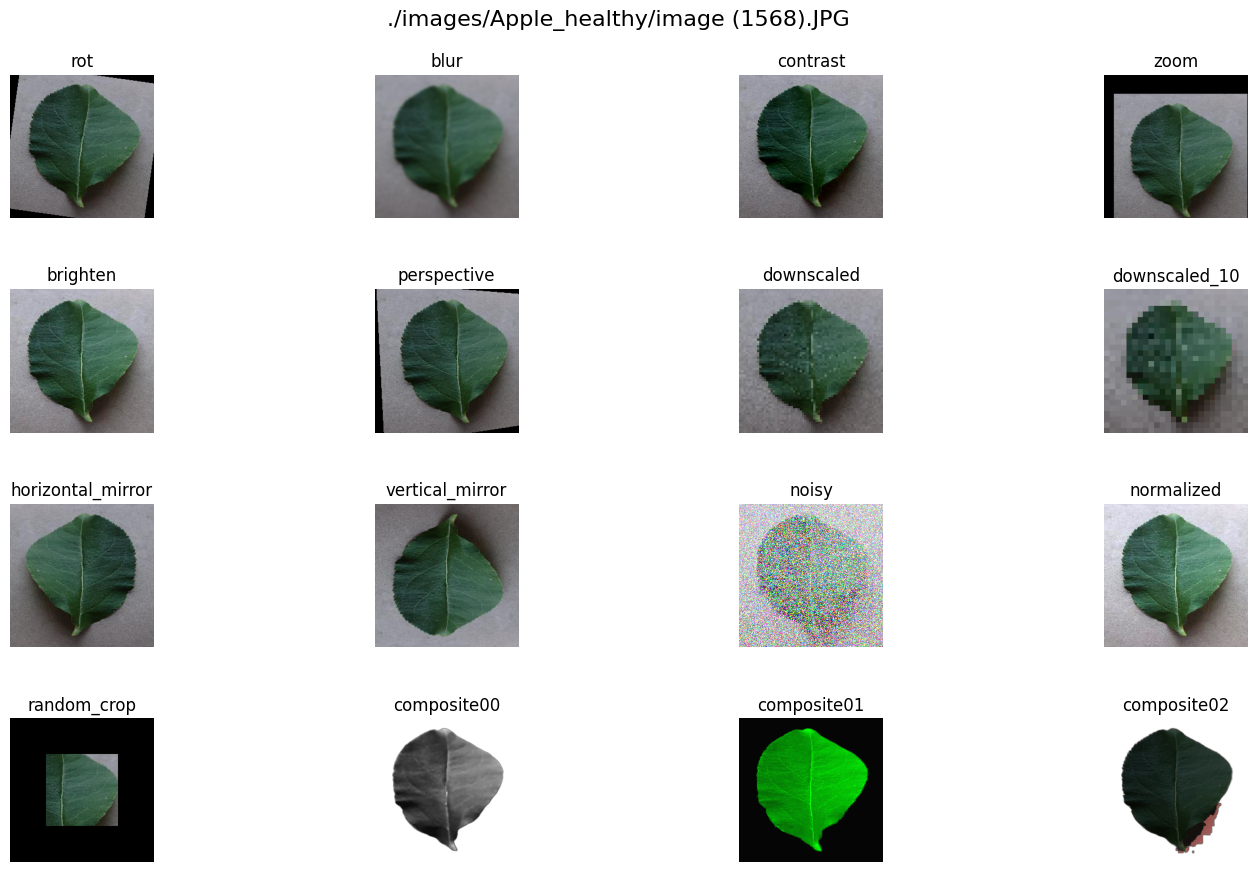

  0%|                                       | 9/7221 [00:52<11:13:27,  5.60s/it]

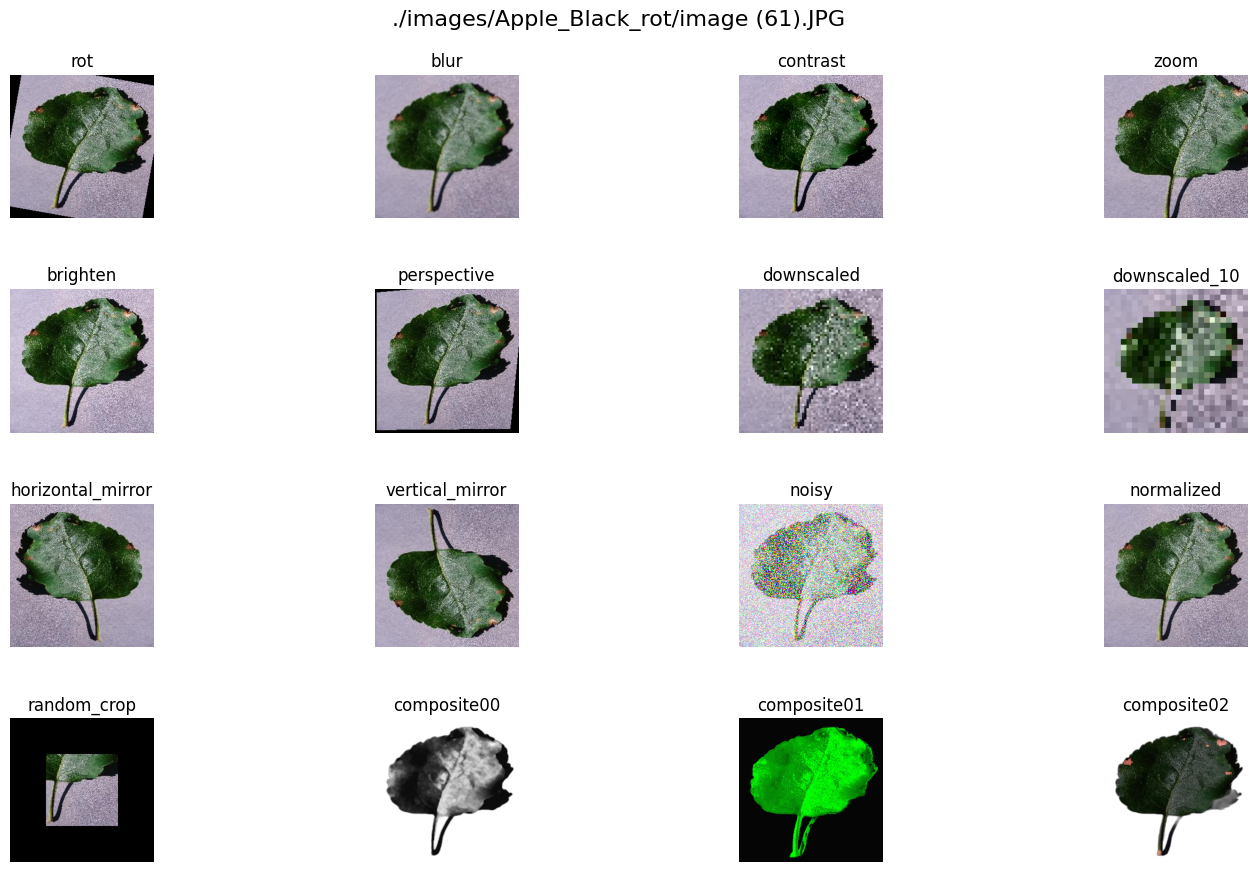

  0%|                                      | 10/7221 [00:58<11:38:46,  5.81s/it]


In [16]:
LeafflictionAugmentation(DATA_FOLDER, export_augmented=False)

In [ ]:
# TODO: 
# - serializable sql db & connector. 
# - create sql db, table, schema
# - Data train/test split + class balancing (ie by limiting access to some examples for over represented classes)
# - define training data structure per input image (Feature engineering?) 
# - batch sql ingestion for transformations
# - 